In [6]:
!pip install qutip

# Jayne - Cummings

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la

#Note : Neglecting 1/2 in photon harmonic oscillator or taking the ground state and excited in atom to be -hw/2 , hw/2 instead of 0 , hw yields the same result.
#We will consider photon modes till 5
nm = 2 #Number of photons in every mode
L = 1
w = 2*np.pi/L*np.array([2]) #number of modes selected
hc = 1
w21 = 4*np.pi
eps = 1

#Initial state
pstate1 = np.array([[1],[0]])
astate = np.array([[0],[1]])

state = np.kron(pstate1,astate)
print("The initials state is",state)

#Radiation Hamiltonian

def radiation_H():
  for i in range(len(w)):
    Hrad = np.zeros([nm,nm])
    for j in range(nm):
      Hrad[j,j] = hc*w[i]*( j +0.5)
    if i == 0:
      HR = Hrad
    else:
      HR = np.kron(HR,Hrad)
  HR = np.kron(HR,np.eye(2))
  return HR

def atomic_H():
  for i in range(len(w)):
    if i == 0:
      HA = np.eye(nm)
    else:
      HA = np.kron(HA,np.eye(nm))
  H_atom = np.array([[0,0],[0,1]])
  HA = np.kron(HA,H_atom)*hc*w21
  return HA

def interaction_H(): #This specifically made for simple case
  H_int = np.zeros([4,4])
  g = (w[0]/(2*hc*eps*L**3))**0.5
  H_int[1,2] = hc*g
  H_int[2,1] = hc*g
  return H_int


HR = radiation_H()
HA = atomic_H()
HI = interaction_H()
H = HR + HA + HI

print("The total Hamiltonian is:",H)
print("The radiation Hamiltonian is:",HR)
print("The atomic Hamiltonian is:",HA)
print("The interaction Hamiltonian is:",HI)

eigs, vecs = np.linalg.eigh(H)

The initials state is [[0]
 [1]
 [0]
 [0]]
The total Hamiltonian is: [[ 6.28318531  0.          0.          0.        ]
 [ 0.         18.84955592  2.50662827  0.        ]
 [ 0.          2.50662827 18.84955592  0.        ]
 [ 0.          0.          0.         31.41592654]]
The radiation Hamiltonian is: [[ 6.28318531  0.          0.          0.        ]
 [ 0.          6.28318531  0.          0.        ]
 [ 0.          0.         18.84955592  0.        ]
 [ 0.          0.          0.         18.84955592]]
The atomic Hamiltonian is: [[ 0.          0.          0.          0.        ]
 [ 0.         12.56637061  0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.         12.56637061]]
The interaction Hamiltonian is: [[0.         0.         0.         0.        ]
 [0.         0.         2.50662827 0.        ]
 [0.         2.50662827 0.         0.        ]
 [0.         0.         0.         0.        ]]


C:\Users\haric\AppData\Local\Temp\ipykernel_23344\3234832124.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  P1[i] = np.abs(evol_state[0])**2
C:\Users\haric\AppData\Local\Temp\ipykernel_23344\3234832124.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  P2[i] = np.abs(evol_state[1])**2
C:\Users\haric\AppData\Local\Temp\ipykernel_23344\3234832124.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  P3[i] = np.abs(evol_state[2])**2
C:\Users\haric\AppData\Local

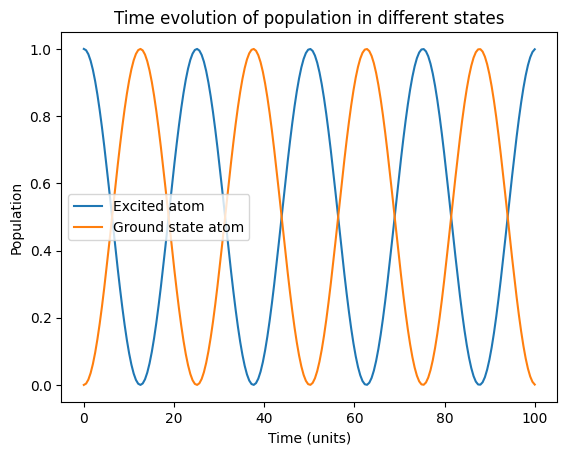

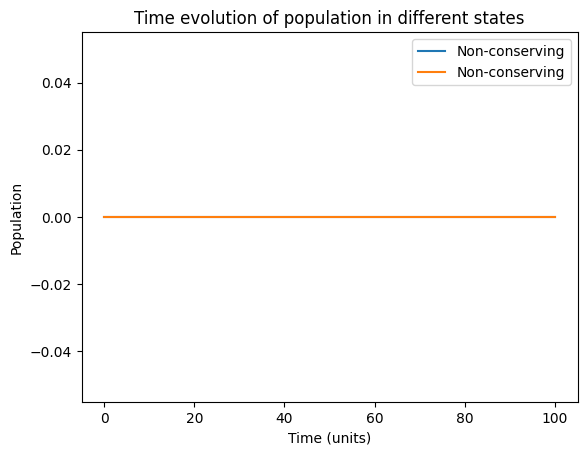

In [8]:
def Unit(H,t):
  exponent = -1j * H * t / hc
  U = la.expm(exponent)
  return U

t = np.linspace(0,100,200)
P1 = np.zeros(len(t))
P2 = np.zeros(len(t))
P3 = np.zeros(len(t))
P4 = np.zeros(len(t))

evol_state = state

for i in range(len(t)):
  U = Unit(H,t[i]/20)
  evol_state = np.dot(U,state) # Note that U(t) acts on initial state not state at t.
  P1[i] = np.abs(evol_state[0])**2
  P2[i] = np.abs(evol_state[1])**2
  P3[i] = np.abs(evol_state[2])**2
  P4[i] = np.abs(evol_state[3])**2

plt.figure(0)
plt.plot(t,P2,label = 'Excited atom')
plt.plot(t,P3,label = 'Ground state atom')
plt.title("Time evolution of population in different states")
plt.xlabel("Time (units)")
plt.ylabel("Population")
plt.legend()
plt.show()

plt.figure(1)
plt.plot(t,P1,label = 'Non-conserving')
plt.plot(t,P4,label = 'Non-conserving')
plt.title("Time evolution of population in different states")
plt.xlabel("Time (units)")
plt.ylabel("Population")
plt.legend()
plt.show()

In [15]:
#Note : Bosonic Amplification of frequency and more photons more is the ability to sustain coupling over detuning
nm = 12 #Max Number of photons in every mode + 1
L = 1
w = 2*np.pi/L*np.array([2]) #1 mode has been selected
hc = 1
w21 = 4*np.pi
eps = 1

#Initial state
pstate1 = np.zeros([nm,1])
nmi = 10 #Number of photons initially is nmi
pstate1[nmi] = 1
astate = np.array([[0],[1]]) #Excited atom

state = np.kron(pstate1,astate)
print("The initial state is",state)

#Radiation Hamiltonian

def radiation_H():
  for i in range(len(w)):
    Hrad = np.zeros([nm,nm])
    for j in range(nm):
      Hrad[j,j] = hc*w[i]*( j +0.5)
    if i == 0:
      HR = Hrad
    else:
      HR = np.kron(HR,Hrad)
  HR = np.kron(HR,np.eye(2))
  return HR

def atomic_H():
  for i in range(len(w)):
    if i == 0:
      HA = np.eye(nm)
    else:
      HA = np.kron(HA,np.eye(nm))
  H_atom = np.array([[0,0],[0,1]])
  HA = np.kron(HA,H_atom)*hc*w21
  return HA

def interaction_H(): #This specifically made for simple case
  H_int = np.zeros([2*nm,2*nm])
  g = (w[0]/(2*hc*eps*L**3))**0.5
  for i in range(1,nm):
    H_int[2*i-1,2*i] = i**0.5*hc*g
    H_int[2*i,2*i-1] = i**0.5*hc*g
  return H_int


HR = radiation_H()
HA = atomic_H()
HI = interaction_H()
H = HR + HA + HI

eigs, vecs = np.linalg.eigh(H)

The initial state is [[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]]


C:\Users\haric\AppData\Local\Temp\ipykernel_23344\3233422745.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  P2[i] = np.abs(evol_state[1])**2
C:\Users\haric\AppData\Local\Temp\ipykernel_23344\3233422745.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  P3[i] = np.abs(evol_state[2])**2
C:\Users\haric\AppData\Local\Temp\ipykernel_23344\3233422745.py:21: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  P_exc[i] = np.abs(evol_state[2*nmi+1])**2
C:\Users\haric\AppD

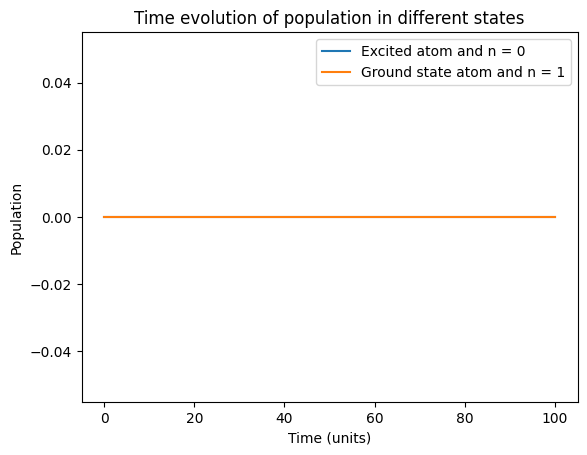

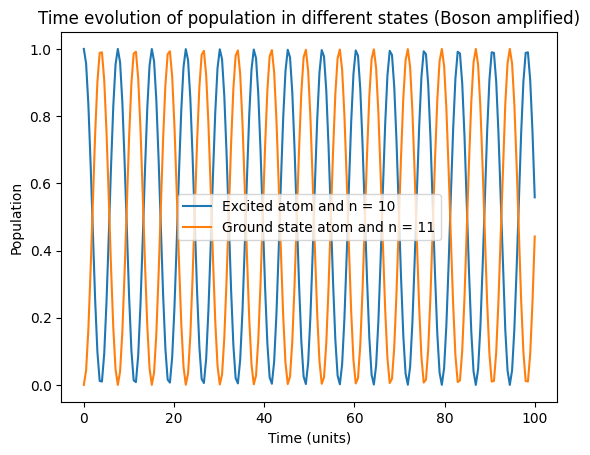

In [10]:
def Unit(H,t):
  exponent = -1j * H * t / hc
  U = la.expm(exponent)
  return U

t = np.linspace(0,100,200)
P2 = np.zeros(len(t))
P3 = np.zeros(len(t))

P_exc = np.zeros(len(t))
P_gro = np.zeros(len(t))

evol_state = state

for i in range(len(t)):
  U = Unit(H,t[i]/20)
  evol_state = np.dot(U,state) # Note that U(t) acts on initial state not state at t.
  P2[i] = np.abs(evol_state[1])**2
  P3[i] = np.abs(evol_state[2])**2

  P_exc[i] = np.abs(evol_state[2*nmi+1])**2
  P_gro[i] = np.abs(evol_state[2*nmi+2])**2

plt.figure(0)
plt.plot(t,P2,label = 'Excited atom and n = 0')
plt.plot(t,P3,label = 'Ground state atom and n = 1')
plt.title("Time evolution of population in different states")
plt.xlabel("Time (units)")
plt.ylabel("Population")
plt.legend()
plt.show()

plt.figure(1)
plt.plot(t,P_exc,label = f'Excited atom and n = {nmi}')
plt.plot(t,P_gro,label = f'Ground state atom and n = {nmi+1}')
plt.title("Time evolution of population in different states (Boson amplified)")
plt.xlabel("Time (units)")
plt.ylabel("Population")
plt.legend()
plt.show()

Analysis of the length variation and effect on the Polaritonic states.

The Hamiltonian in matrix form is [[ 3.14159265  0.          0.          0.        ]
 [ 0.         15.70796327  1.77245385  0.        ]
 [ 0.          1.77245385  9.42477796  0.        ]
 [ 0.          0.          0.         21.99114858]]
The eigen values are: [ 3.14159265  8.95926692 16.17347431 21.99114858]


C:\Users\haric\AppData\Local\Temp\ipykernel_23344\2836712662.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Hrad[j,j] = hc*w*( j +0.5)
C:\Users\haric\AppData\Local\Temp\ipykernel_23344\2836712662.py:48: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  H_int[1,2] = hc*g
C:\Users\haric\AppData\Local\Temp\ipykernel_23344\2836712662.py:49: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  H_int[2,1] = hc*g


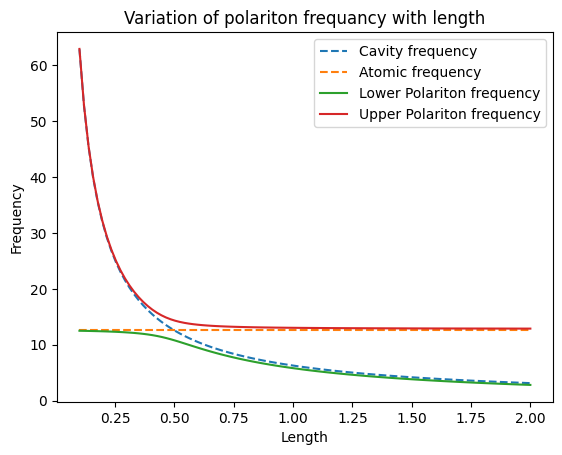

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la

#Note : Neglecting 1/2 in photon harmonic oscillator or taking the ground state and excited in atom to be -hw/2 , hw/2 instead of 0 , hw yields the same result.
#We will consider photon modes till 5
nm = 2 #Number of photons in every mode
L = 1
A = 1
w = 2*np.pi/L*np.array([1]) #1 mode has been selected
hc = 1
w21 = 4*np.pi
eps = 1

#Initial state
pstate1 = np.array([[1],[0]])
astate = np.array([[0],[1]])

state = np.kron(pstate1,astate)

#Radiation Hamiltonian

def radiation_H(w,w21):
  for i in range(1):
    Hrad = np.zeros([nm,nm])
    for j in range(nm):
      Hrad[j,j] = hc*w*( j +0.5)
    if i == 0:
      HR = Hrad
    else:
      HR = np.kron(HR,Hrad)
  HR = np.kron(HR,np.eye(2))
  return HR

def atomic_H(w,w21):
  for i in range(1):
    if i == 0:
      HA = np.eye(nm)
    else:
      HA = np.kron(HA,np.eye(nm))
  H_atom = np.array([[0,0],[0,1]])
  HA = np.kron(HA,H_atom)*hc*w21
  return HA

def interaction_H(): #This specifically made for simple case
  H_int = np.zeros([4,4])
  g = (w/(2*hc*eps*A*L))**0.5
  H_int[1,2] = hc*g
  H_int[2,1] = hc*g
  return H_int


HR = radiation_H(w,w21)
HA = atomic_H(w,w21)
HI = interaction_H()
H = HR + HA + HI

print("The Hamiltonian in matrix form is",H)

eigs, vecs = np.linalg.eigh(H)
print("The eigen values are:",eigs)

L1 = np.linspace(0.1,2,100)
w1 = 2*np.pi/L1
w21_ = np.ones(100) * w21
eig1 = np.zeros(100)
eig2 = np.zeros(100)

for i in range(0,100):
  HR = radiation_H(w1[i],w21)
  HA = atomic_H(w1[i],w21)
  HI = interaction_H()
  H = HR + HA + HI

  eigs = np.linalg.eigvalsh(H[1:3, 1:3])        # Diagnalizing the subspace corresponding to energy conserved states.
  eig1[i] = eigs[0] - 0.5*w1[i]
  eig2[i] = eigs[1] - 0.5*w1[i]

plt.figure()
plt.plot(L1,w1,label = "Cavity frequency", linestyle = "--" )
plt.plot(L1,w21_,label = "Atomic frequency", linestyle = "--" )
plt.plot(L1,eig1  ,label = "Lower Polariton frequency" )
plt.plot(L1,eig2  ,label = "Upper Polariton frequency" )
plt.title("Variation of polariton frequancy with length")
plt.xlabel("Length")
plt.ylabel("Frequency")
plt.legend()
plt.show()

The polariton curve matches the expectation. The value of g is fixed to the resonant condition and is not dependent on the cavity length in the above plot.